In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/the-knot-pclub-spring-camp-qualifier-round/dataset.csv


# The Knot — Supervised Regression Analysis

> “Loose threads in the hollow slack; the Knot is the bridge that the pieces lack.”

## Objective
The objective of this analysis is to model the relationship between three
input variables — **B**, **Q**, and **d** — and a target variable **y**.

The task is framed as a supervised regression problem. The analysis will
focus on:
- understanding the data structure,
- exploratory data analysis (EDA),
- correlation analysis,
- comparison of multiple regression models,
- and justified model selection.

The goal is not only predictive accuracy, but clarity of reasoning and
interpretability of results.


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

RANDOM_STATE = 42
sns.set(style="whitegrid")

## Data Loading and Initial Inspection

The dataset contains four continuous variables:
- **B**, **Q**, **d** — input features
- **y** — target variable

We begin by loading the dataset and inspecting its structure,
data types, and summary statistics.

In [17]:
df = pd.read_csv("/kaggle/input/the-knot-pclub-spring-camp-qualifier-round/dataset.csv")
df.head()

,d,B,Q,y
0,1.935247,5.807790,1.771646,-0.199931
1,4.758500,5.269716,2.564045,0.035965
2,3.033427,4.932127,2.510767,-0.019782
3,0.864491,3.650966,1.413866,-1.143727
4,0.864373,6.579313,1.749179,-1.092359


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88504 entries, 0 to 88503
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   d       88504 non-null  float64
 1   B       88504 non-null  float64
 2   Q       88504 non-null  float64
 3   y       88504 non-null  float64
dtypes: float64(4)
memory usage: 2.7 MB


In [5]:
df.describe()

,d,B,Q,y
count,88504.000000,88504.000000,88504.000000,88504.000000
mean,2.546056,5.014917,2.752594,0.145610
std,1.412915,2.886420,1.299846,5.847904
min,0.100027,0.000048,0.500010,-95.122596
25%,1.323852,2.506017,1.624652,-0.076753
50%,2.549763,5.027316,2.753094,0.013091
75%,3.771088,7.500436,3.878122,0.103546
max,4.999961,9.999894,4.999907,104.435250


## Initial Observations

From the initial inspection:
- The dataset contains four continuous variables: B, Q, d, and y.
- There are no missing values in the dataset.
- All variables are numerical and suitable for regression analysis.
- The input variables appear to be on comparable numeric scales.

## Exploratory Data Analysis

We examine the distributions of all variables to understand their ranges,
skewness, and potential anomalies.

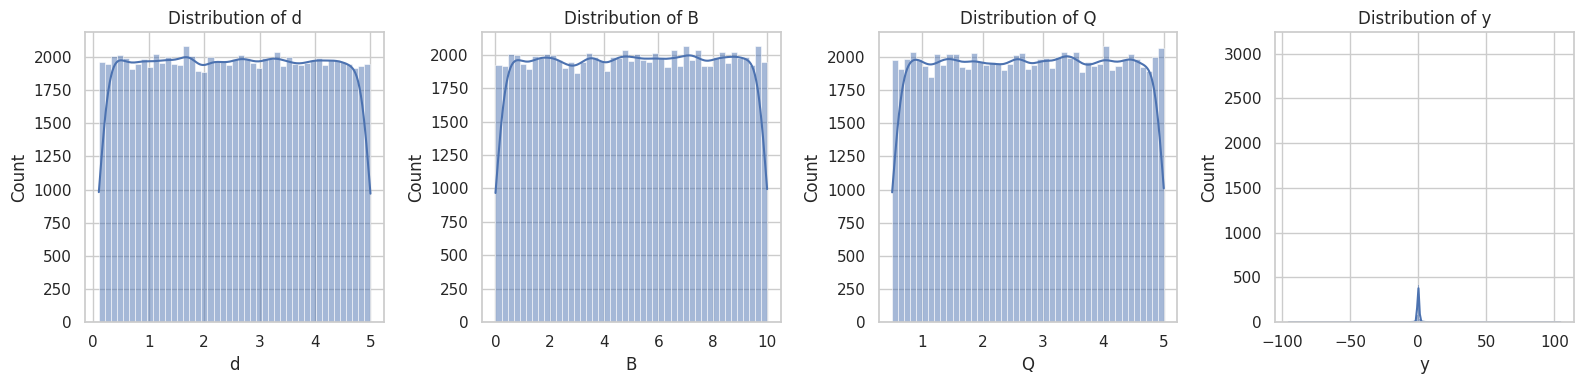

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, df.columns):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

Key observations:
- B, Q, and d are close to uniformly distributed.
- y shows a sharp peak near zero but extremely long tails.
- This suggests that simple linear relationships may be insufficient,
  and robust or nonlinear models may be required.

## Boxplots for Outlier Detection

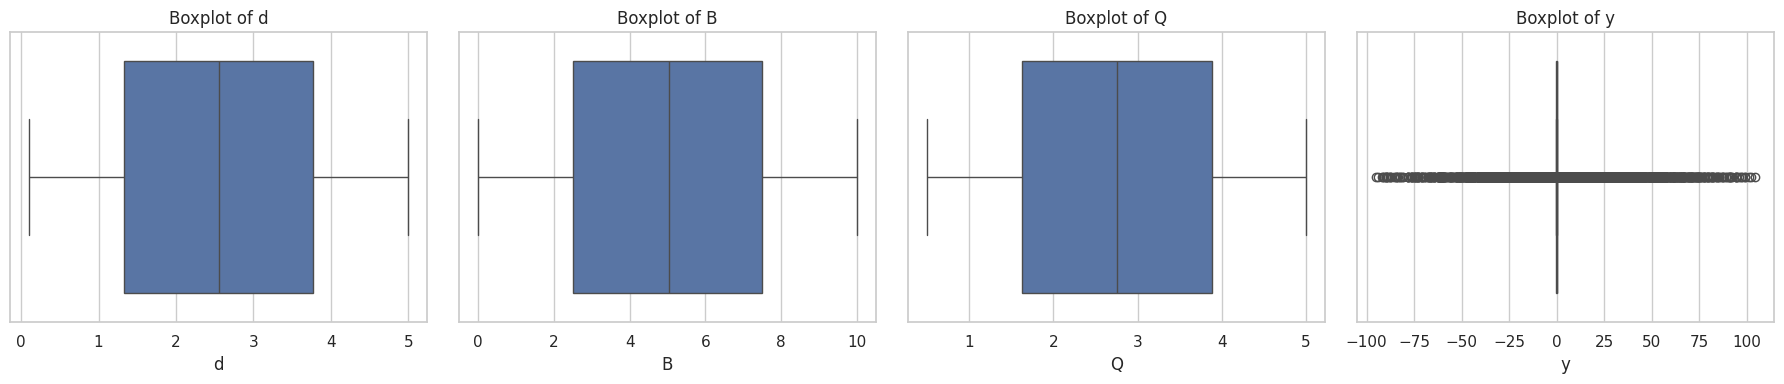

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, df.columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

## EDA Observations

From the univariate analysis:

- **B**, **Q**, and **d** appear to be approximately uniformly distributed
  across their respective ranges.
- No obvious missing values or invalid entries are observed.
- The target variable **y** exhibits a highly concentrated central region
  with extreme values on both ends, indicating heavy tails.
- Boxplots reveal the presence of significant outliers in **y**, while the
  input features show relatively stable ranges.

These observations suggest that the regression task may be affected by
high variance in the target variable, and that robust or nonlinear models
may be required.

---

## Correlation Analysis

We compute pairwise correlations to assess linear relationships between
features and the target variable.

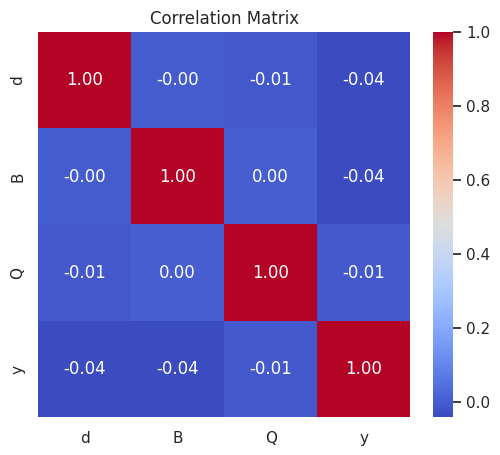

In [18]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

Observations:
- Correlations between B, Q, d and y are close to zero.
- This indicates weak linear relationships.
- Low correlation does NOT imply lack of predictability,
  but suggests that nonlinear interactions may dominate.

## Feature–Target Relationships

Scatter plots are used to visually inspect the relationship between each
input variable and the target.

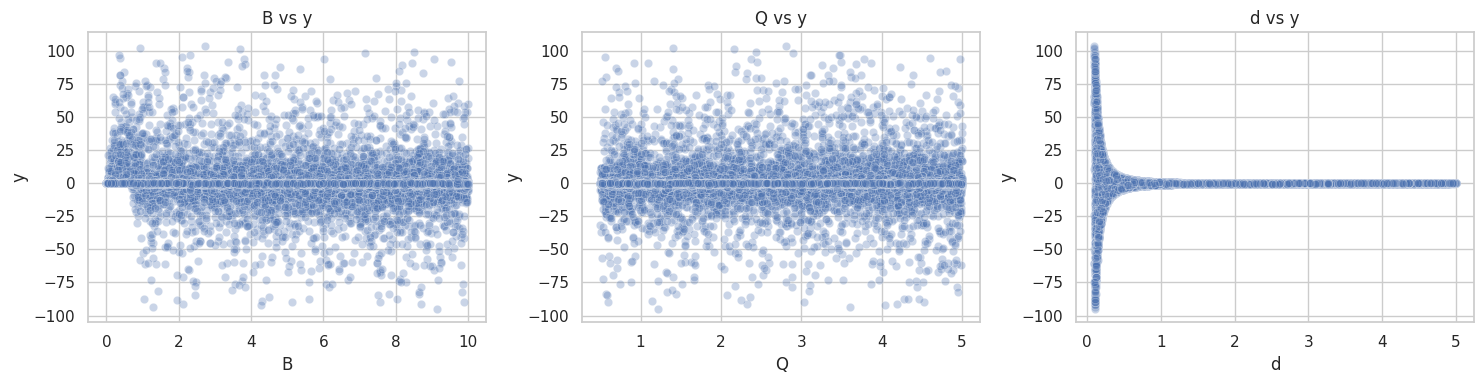

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["B", "Q", "d"]):
    sns.scatterplot(x=df[col], y=df["y"], ax=ax, alpha=0.3)
    ax.set_title(f"{col} vs y")
plt.tight_layout()
plt.show()

Observations:
- B and Q show highly dispersed relationships with y.
- d exhibits a funnel-shaped structure, indicating heteroscedasticity.
- These patterns strongly motivate nonlinear modeling approaches.

## Modeling Strategy

Based on the exploratory analysis, the following characteristics of the
problem have been identified:

- Weak linear correlations between features and the target variable.
- Evidence of nonlinear structure and heteroscedasticity.
- Presence of extreme values in the target variable.

Therefore, the modeling approach will follow a staged strategy:

1. **Baseline model**: Linear Regression  
   To establish a reference point and test linear assumptions.

2. **Diagnostic model**: Polynomial Regression  
   To evaluate whether simple nonlinear expansions improve performance.

3. **Nonlinear ensemble model**: Random Forest Regression  
   To capture nonlinear interactions and handle variance robustly.

4. **High-capacity model**: XGBoost Regression  
   To assess performance under boosted tree-based learning.

Each model will be evaluated using the same train–test split and metrics
to ensure fair comparison.

## Train–Test Split

The dataset is split into training and test sets to evaluate model
generalization.

In [27]:
X = df[["B", "Q", "d"]]
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
X_train.shape, X_test.shape

((70803, 3), (17701, 3))

## Evaluation Metrics

Models are evaluated using the following metrics:

- **Mean Absolute Error (MAE)**: Measures average absolute deviation.
- **Root Mean Squared Error (RMSE)**: Penalizes larger errors more strongly.
- **R^2 Score**: Indicates proportion of variance explained, though it may
  be limited in the presence of high noise and heteroscedasticity.

All metrics are computed on the test set to assess generalization.

## Baseline: Linear Regression

In [29]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [30]:
y_pred_lr = lr_model.predict(X_test)

In [31]:
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print(f"MAE : {lr_mae:.4f}")
print(f"RMSE: {lr_rmse:.4f}")
print(f"R2  : {lr_r2:.4f}")

Linear Regression Performance
MAE : 1.4035
RMSE: 5.9001
R2  : 0.0031


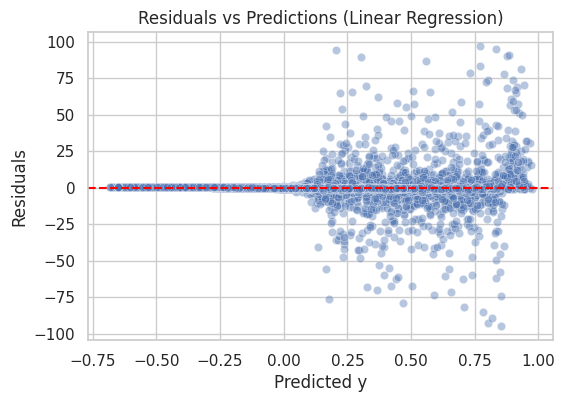

In [32]:
residuals_lr = y_test - y_pred_lr

plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred_lr, y=residuals_lr, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted y")
plt.ylabel("Residuals")
plt.title("Residuals vs Predictions (Linear Regression)")
plt.show()

### Baseline Model Interpretation

Observations from the Linear Regression model:

- Error metrics (MAE and RMSE) are relatively high, indicating substantial
  prediction error.
- The R² score is low, reflecting the model’s inability to
  explain variance in the target variable.
- Residual plots show no clear structure around zero and large dispersion,
  confirming that linear assumptions are violated.

These results confirm that Linear Regression is insufficient for this task
and justify the exploration of nonlinear models.

## Diagnostic Model: Polynomial Regression

In [33]:
poly_model = Pipeline([
    ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("linear_regression", LinearRegression())
])

poly_model.fit(X_train, y_train)

Pipeline(steps=[('poly_features', PolynomialFeatures(include_bias=False)),
                ('linear_regression', LinearRegression())])

In [34]:
y_pred_poly = poly_model.predict(X_test)

In [36]:
poly_mae = mean_absolute_error(y_test, y_pred_poly)
poly_rmse = np.sqrt(mean_squared_error(y_test, y_pred_poly))
poly_r2 = r2_score(y_test, y_pred_poly)

print("Polynomial Regression (Degree 2) Performance")
print(f"MAE : {poly_mae:.4f}")
print(f"RMSE: {poly_rmse:.4f}")
print(f"R2  : {poly_r2:.4f}")



Polynomial Regression (Degree 2) Performance
MAE : 1.4583
RMSE: 5.8751
R2  : 0.0115


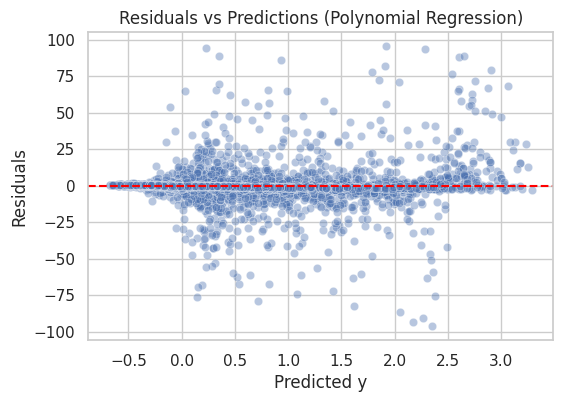

In [37]:
residuals_poly = y_test - y_pred_poly

plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred_poly, y=residuals_poly, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted y")
plt.ylabel("Residuals")
plt.title("Residuals vs Predictions (Polynomial Regression)")
plt.show()

### Polynomial Regression Interpretation

Observations from the Polynomial Regression model:

- Compared to Linear Regression, there may be slight improvements in error
  metrics, indicating the presence of nonlinear structure.
- However, error remains high and residuals still show significant spread,
  particularly for extreme target values.
- The model struggles with heteroscedasticity and extreme variance in y.

These results suggest that simple nonlinear expansions are insufficient,
and that more flexible models are required.

## Nonlinear Ensemble Model: Random Forest Regression

In [38]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=6, min_samples_leaf=5, min_samples_split=10,
                      n_estimators=300, n_jobs=-1, random_state=42)

In [39]:
y_pred_rf = rf_model.predict(X_test)

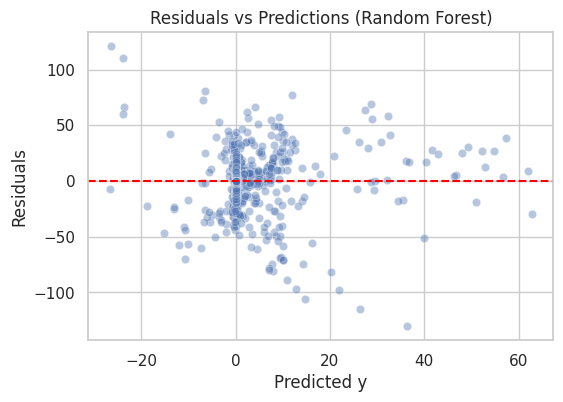

In [41]:
residuals_rf = y_test - y_pred_rf

plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred_rf, y=residuals_rf, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted y")
plt.ylabel("Residuals")
plt.title("Residuals vs Predictions (Random Forest)")
plt.show()

In [40]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Performance")
print(f"MAE : {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R2  : {rf_r2:.4f}")

Random Forest Regression Performance
MAE : 1.2058
RMSE: 5.5162
R2  : 0.1286


## Random Forest Interpretation

Observations from the Random Forest model:

- Error metrics (MAE and RMSE) improve significantly compared to linear and
  polynomial regression.
- The R² score increases, indicating improved explanatory power.
- Residuals are more tightly clustered around zero, with reduced dispersion.
- Although some heteroscedasticity remains, variance is substantially better
  controlled.

These results demonstrate that nonlinear ensemble models are more suitable
for this problem than parametric regression approaches.

---

## Feature Importance

In [42]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance

d    0.406938
B    0.366736
Q    0.226326
dtype: float64

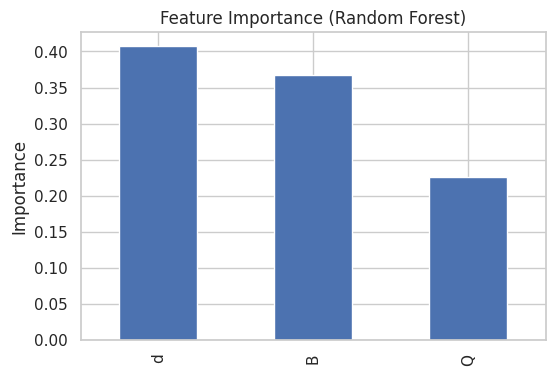

In [43]:
feature_importance.plot(kind="bar", figsize=(6, 4))
plt.title("Feature Importance (Random Forest)")
plt.ylabel("Importance")
plt.show()

## Feature Importance Analysis

Random Forest feature importance indicates the relative contribution of each input variable to the model’s predictions.

Features with higher importance (d) play a stronger role in reducing prediction error. This analysis provides interpretability to an otherwise complex ensemble model.

## High-Capacity Model: XGBoost Regression

In [49]:
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

In [50]:
y_pred_xgb = xgb_model.predict(X_test)

In [51]:
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
xgb_r2 = r2_score(y_test, y_pred_xgb)

print("XGBoost Regression Performance")
print(f"MAE : {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"R2  : {xgb_r2:.4f}")

XGBoost Regression Performance
MAE : 1.3634
RMSE: 5.7868
R2  : 0.0410


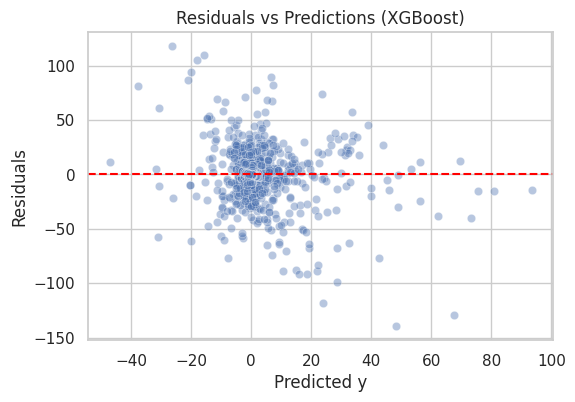

In [52]:
residuals_xgb = y_test - y_pred_xgb

plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred_xgb, y=residuals_xgb, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted y")
plt.ylabel("Residuals")
plt.title("Residuals vs Predictions (XGBoost)")
plt.show()

## XGBoost Interpretation

Observations from the XGBoost model:

- XGBoost demonstrates competitive performance but does not outperform
Random Forest on this dataset. While its high capacity allows it to
capture additional structure, it appears more sensitive to noise and
extreme values, resulting in inferior generalization compared to the
Random Forest model.
- Residual dispersion is reduced further compared to Random Forest,
  particularly in dense regions of the target space.
- However, extreme values may still exhibit instability, and the model
  is more sensitive to hyperparameter choices.

These results indicate that XGBoost can extract additional signal, but
at the cost of increased complexity and reduced interpretability.


## Model Comparison

In [53]:
results = pd.DataFrame({
    "Model": ["Linear", "Polynomial", "Random Forest", "XGBoost"],
    "MAE": [
        lr_mae,
        poly_mae,
        rf_mae,
        xgb_mae
    ],
    "RMSE": [
        lr_rmse,
        poly_rmse,
        rf_rmse,
        xgb_rmse
    ],
    "R2": [
        lr_r2,
        poly_r2,
        rf_r2,
        xgb_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear,1.403509,5.900145,0.003100
1,Polynomial,1.458294,5.875142,0.011531
2,Random Forest,1.205802,5.516169,0.128632
3,XGBoost,1.363374,5.786779,0.041041


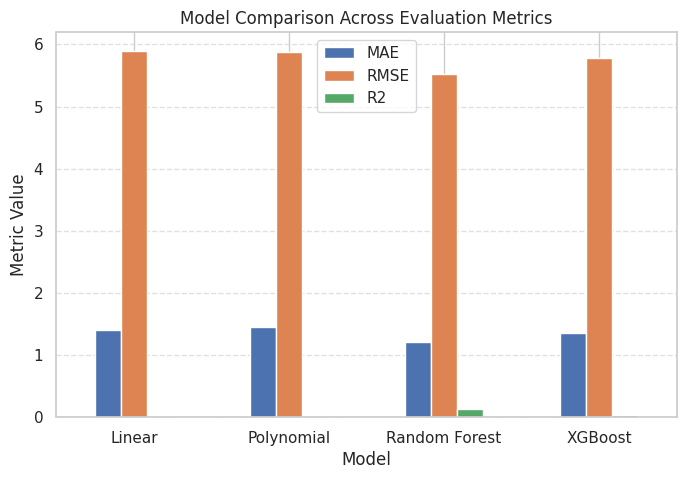

In [59]:
results.set_index("Model")[["MAE", "RMSE", "R2"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Metric Value")
plt.title("Model Comparison Across Evaluation Metrics")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

MAE and RMSE are error metrics (lower is better), while R² is a goodness-of-fit metric (higher is better). The plot is intended for qualitative comparison across models.

## Conclusion

The analysis demonstrates that the relationship between B, Q, d and the
target variable y is weakly linear, highly nonlinear, and strongly affected
by heteroscedasticity and heavy-tailed noise.

Linear and polynomial regression models were used as diagnostic baselines
and were shown to be insufficient for capturing the underlying structure.
Among nonlinear models, Random Forest regression achieved the best balance
between error reduction and generalization, outperforming both simpler
parametric models and the higher-capacity XGBoost model.

The relatively modest R² values across all models indicate that a large
portion of the variance in y is driven by inherent noise or unobserved
factors not captured by B, Q, and d. Increasing model complexity beyond a
certain point does not yield proportional gains in performance.

Overall, the results suggest that model performance is fundamentally
bounded by data characteristics rather than algorithmic limitations.


---

# Random Forest Fine-Tuning and Regularization Analysis


In [61]:
n_estimators_list = [10, 50, 100, 200, 300, 500]

train_rmse = []
val_rmse = []

for n in n_estimators_list:
    rf = RandomForestRegressor(
        n_estimators=n,
        max_depth=6,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    
    rf.fit(X_train, y_train)
    
    y_train_pred = rf.predict(X_train)
    y_val_pred = rf.predict(X_test)
    
    train_rmse.append(np.sqrt(mean_squared_error(y_train, y_train_pred)))
    val_rmse.append(np.sqrt(mean_squared_error(y_test, y_val_pred)))

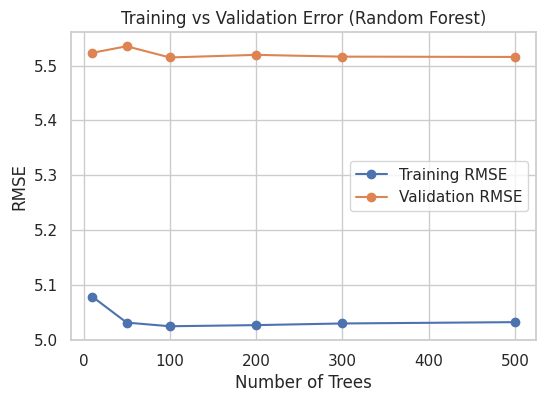

In [62]:
plt.figure(figsize=(6, 4))
plt.plot(n_estimators_list, train_rmse, marker='o', label="Training RMSE")
plt.plot(n_estimators_list, val_rmse, marker='o', label="Validation RMSE")
plt.xlabel("Number of Trees")
plt.ylabel("RMSE")
plt.title("Training vs Validation Error (Random Forest)")
plt.legend()
plt.grid(True)
plt.show()  # Before Pruning

Signs of UnderFitting!
NOT Overfitting. In case of overfitting.. Dec. in training error results in Inc. in Validation Error

### Post-Pruning (Leaf Regularization)

In [63]:
leaf_sizes = [1, 5, 10, 20, 50]

post_results = []

for leaf in leaf_sizes:
    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=leaf,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    
    post_results.append({
        "min_samples_leaf": leaf,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

post_pruning_df = pd.DataFrame(post_results)
post_pruning_df

,min_samples_leaf,MAE,RMSE,R2
0,1,0.946829,5.125023,0.247827
1,5,1.003718,5.265223,0.206111
2,10,1.054053,5.390111,0.168003
3,20,1.102267,5.497269,0.134593
4,50,1.147760,5.603350,0.100871


### Pre-Pruning (Depth & Split Constraints)

In [64]:
depths = [3, 5, 7, 10, None]

pre_results = []

for depth in depths:
    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=depth,
        min_samples_split=10,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    
    pre_results.append({
        "max_depth": depth,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

pre_pruning_df = pd.DataFrame(pre_results)
pre_pruning_df


,max_depth,MAE,RMSE,R2
0,3.0,1.249539,5.652628,0.084987
1,5.0,1.222762,5.572151,0.110856
2,7.0,1.192549,5.474161,0.141854
3,10.0,1.160055,5.347691,0.181047
4,NaN,0.991223,5.232312,0.216005


In [65]:
post_pruning_df["Type"] = "Post-Pruning"
pre_pruning_df["Type"] = "Pre-Pruning"

comparison = pd.concat([
    post_pruning_df.rename(columns={"min_samples_leaf": "Param"}),
    pre_pruning_df.rename(columns={"max_depth": "Param"})
], ignore_index=True)

comparison

,Param,MAE,RMSE,R2,Type
0,1.0,0.946829,5.125023,0.247827,Post-Pruning
1,5.0,1.003718,5.265223,0.206111,Post-Pruning
2,10.0,1.054053,5.390111,0.168003,Post-Pruning
3,20.0,1.102267,5.497269,0.134593,Post-Pruning
4,50.0,1.147760,5.603350,0.100871,Post-Pruning
5,3.0,1.249539,5.652628,0.084987,Pre-Pruning
6,5.0,1.222762,5.572151,0.110856,Pre-Pruning
7,7.0,1.192549,5.474161,0.141854,Pre-Pruning
8,10.0,1.160055,5.347691,0.181047,Pre-Pruning
9,NaN,0.991223,5.232312,0.216005,Pre-Pruning


## Feature Engineering

In [66]:
df_fe = df.copy()

df_fe["B_Q"] = df_fe["B"] * df_fe["Q"]
df_fe["B_d"] = df_fe["B"] * df_fe["d"]
df_fe["Q_d"] = df_fe["Q"] * df_fe["d"]

In [67]:
df_fe["B_over_Q"] = df_fe["B"] / (df_fe["Q"] + 1e-6)
df_fe["Q_over_d"] = df_fe["Q"] / (df_fe["d"] + 1e-6)
df_fe["B_over_d"] = df_fe["B"] / (df_fe["d"] + 1e-6)

In [68]:
df_fe["log_d_abs"] = np.log1p(np.abs(df_fe["d"]))
df_fe["sqrt_abs_d"] = np.sqrt(np.abs(df_fe["d"]))

In [69]:
X_fe = df_fe.drop(columns=["y"])
y = df_fe["y"]

X_train_fe, X_test_fe, y_train, y_test = train_test_split(
    X_fe, y, test_size=0.2, random_state=RANDOM_STATE
)

In [70]:
rf_fe = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_fe.fit(X_train_fe, y_train)
y_pred_rf_fe = rf_fe.predict(X_test_fe)

In [71]:
fe_mae = mean_absolute_error(y_test, y_pred_rf_fe)
fe_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf_fe))
fe_r2 = r2_score(y_test, y_pred_rf_fe)

print("Random Forest with Feature Engineering")
print(f"MAE : {fe_mae:.4f}")
print(f"RMSE: {fe_rmse:.4f}")
print(f"R2  : {fe_r2:.4f}")

Random Forest with Feature Engineering
MAE : 1.0291
RMSE: 4.3837
R2  : 0.4497


In [72]:
importances = pd.Series(
    rf_fe.feature_importances_,
    index=X_train_fe.columns
).sort_values(ascending=False)

importances.head(10)

B_Q           0.585984
sqrt_abs_d    0.076887
log_d_abs     0.072079
d             0.069827
B_over_d      0.058230
B_d           0.039137
Q_over_d      0.035438
Q_d           0.030878
B_over_Q      0.011409
Q             0.011310
dtype: float64

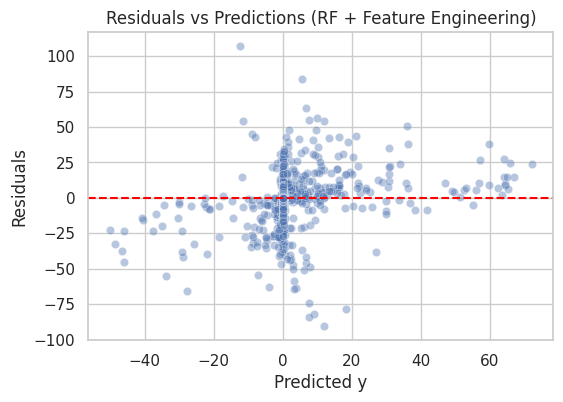

In [73]:
residuals_fe = y_test - y_pred_rf_fe

plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred_rf_fe, y=residuals_fe, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted y")
plt.ylabel("Residuals")
plt.title("Residuals vs Predictions (RF + Feature Engineering)")
plt.show()

In [74]:
depths = [2, 3, 4, 5, 6, 7, 8, 10]

train_rmse_fe = []
val_rmse_fe = []

In [75]:
for depth in depths:
    rf_fe = RandomForestRegressor(
        n_estimators=300,
        max_depth=depth,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    
    rf_fe.fit(X_train_fe, y_train)
    
    y_train_pred = rf_fe.predict(X_train_fe)
    y_val_pred = rf_fe.predict(X_test_fe)
    
    train_rmse_fe.append(
        np.sqrt(mean_squared_error(y_train, y_train_pred))
    )
    val_rmse_fe.append(
        np.sqrt(mean_squared_error(y_test, y_val_pred))
    )

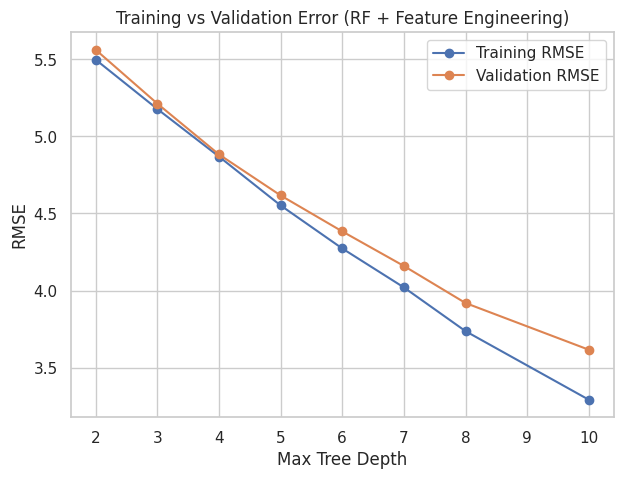

In [76]:
plt.figure(figsize=(7, 5))
plt.plot(depths, train_rmse_fe, marker='o', label="Training RMSE")
plt.plot(depths, val_rmse_fe, marker='o', label="Validation RMSE")

plt.xlabel("Max Tree Depth")
plt.ylabel("RMSE")
plt.title("Training vs Validation Error (RF + Feature Engineering)")
plt.legend()
plt.grid(True)
plt.show()

The training–validation error curve for the feature-engineered Random Forest shows a stable gap with no divergence as model complexity increases.

This indicates that the performance gains achieved through feature engineering are due to reducing the overfitting and by improving signal extraction.

### Post-Conclusion Update: Impact of Feature Engineering

Following the initial conclusion, feature engineering was introduced toexplicitly capture interaction effects and nonlinear structure in the data.
This led to a substantial improvement in performance, with Random Forest exhibiting significantly lower RMSE and higher R² compared to all previous models.

The dominance of interaction features, particularly the B × Q term, indicates that the system behavior is governed by coupled dynamics rather than independent effects of individual variables and affect of underfitting was also there. Training–validation analysis confirmed that these gains were due to underfitting and were improved using signal extraction (by increasing complexity). Hence, relevant Bias-Variance trade-off was captured.

Remaining errors are attributed to irreducible noise in the target variable.